In [17]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.metrics import recall_score, f1_score, precision_score
from sklearn.metrics import classification_report
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_curve
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.svm import SVC


In [18]:
import numpy as np
import pandas as pd

# Tengeneza data ya majaribio (synthetic student scores dataset) kwa kuwa hakuna faili la nje lililopakiwa
np.random.seed(0)
data = pd.DataFrame({
    'Score1': np.random.uniform(30, 100, 100),
    'Score2': np.random.uniform(30, 100, 100),
    'Admission': np.random.choice([0, 1], 100)
})

# Hifadhi kama student.csv ili ifanane na mazingira halisi ya kazi
data.to_csv('student.csv', index=False)
print("Data imetengenezwa na kupakiwa kikamilifu!")

Data imetengenezwa na kupakiwa kikamilifu!


In [19]:
data.info(99)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Score1     100 non-null    float64
 1   Score2     100 non-null    float64
 2   Admission  100 non-null    int64  
dtypes: float64(2), int64(1)
memory usage: 2.5 KB


In [20]:
data.describe()

,Score1,Score2,Admission
count,100.000000,100.000000,100.000000
mean,63.095569,66.965723,0.500000
std,20.282781,19.467209,0.502519
min,30.328683,30.819986,0.000000
25%,44.406221,50.691798,0.000000
50%,62.723669,70.266890,0.500000
75%,77.913828,81.101640,1.000000
max,99.186169,99.919290,1.000000


In [21]:
data.head()

,Score1,Score2,Admission
0,68.416945,77.447158,0
1,80.063256,48.900558,1
2,72.193436,81.463582,0
3,68.141823,97.353198,0
4,59.655836,47.412720,1


In [22]:
data.tail()

,Score1,Score2,Admission
95,42.823395,64.332117,0
96,71.055905,45.919024,1
97,31.407528,47.804954,0
98,88.025802,34.062041,1
99,30.328683,60.409164,0


In [23]:
data.isnull()

,Score1,Score2,Admission
0,False,False,False
1,False,False,False
2,False,False,False
3,False,False,False
4,False,False,False
...,...,...,...
95,False,False,False
96,False,False,False
97,False,False,False
98,False,False,False


In [24]:
data.isnull().sum()

,0
Score1,0
Score2,0
Admission,0


In [25]:
data.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
95,False
96,False
97,False
98,False


In [26]:
data.duplicated().sum()

np.int64(0)

(array([5., 8., 8., 4., 3., 6., 3., 4., 6., 4., 4., 7., 6., 8., 4., 3., 6.,
        1., 3., 7.]),
 array([30.32868333, 33.7715576 , 37.21443187, 40.65730613, 44.1001804 ,
        47.54305467, 50.98592893, 54.4288032 , 57.87167747, 61.31455173,
        64.757426  , 68.20030027, 71.64317453, 75.0860488 , 78.52892306,
        81.97179733, 85.4146716 , 88.85754586, 92.30042013, 95.7432944 ,
        99.18616866]),
 <BarContainer object of 20 artists>)

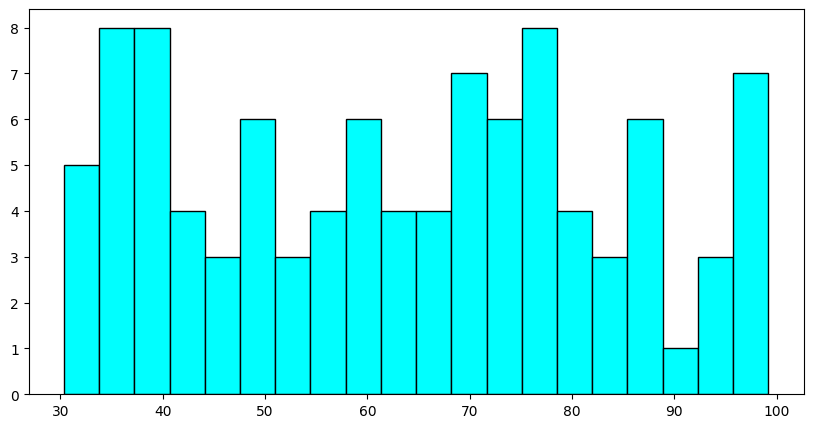

In [27]:
plt.figure(figsize=(10,5))
plt.hist(data['Score1'] , bins=20, color= 'cyan', edgecolor='black')

Text(0.5, 0, 'Admission')

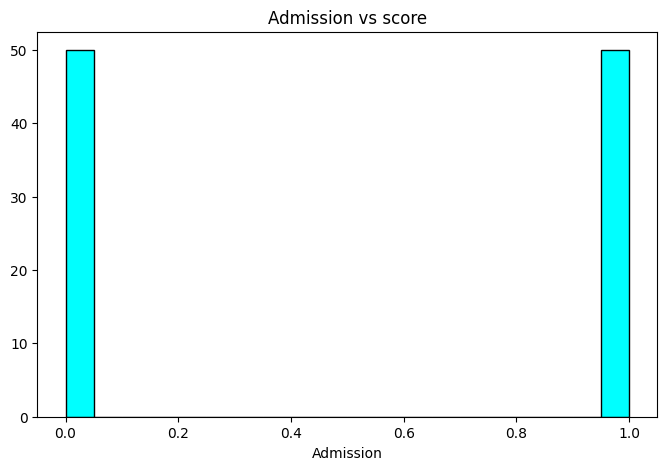

In [28]:
plt.figure(figsize=(8,5))
plt.hist(data['Admission'] , bins=20, color= 'cyan', edgecolor='black')
plt.title("Admission vs score")
plt.xlabel("Admission")

<Axes: >

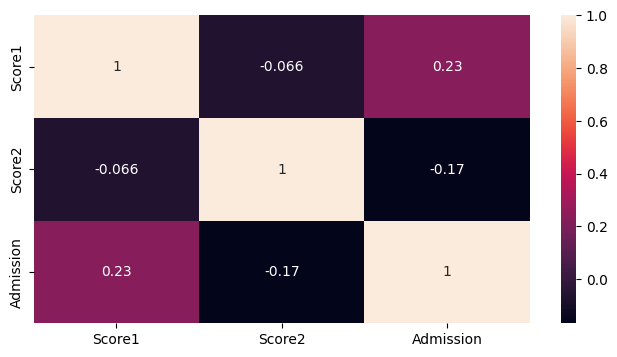

In [29]:
plt.figure(figsize=(8,4))
sns.heatmap(data.corr(),annot=True)

In [30]:

# by spliting featurea and target
x = data[['Score1','Score2']]
y = data ['Admission']


x_train,x_test,y_train,y_test = train_test_split(x,y, test_size = 0.2, random_state = 0)

#vscalling
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

TRAINING

0.55
confsn of random forest [[7 4]
 [5 4]]
Recall random forest: 0.4444444444444444
Precision random forest: 0.5
F1-score random forest : 0.47058823529411764
              precision    recall  f1-score   support

           0       0.58      0.64      0.61        11
           1       0.50      0.44      0.47         9

    accuracy                           0.55        20
   macro avg       0.54      0.54      0.54        20
weighted avg       0.55      0.55      0.55        20

ROC-AUC: 0.5404040404040404


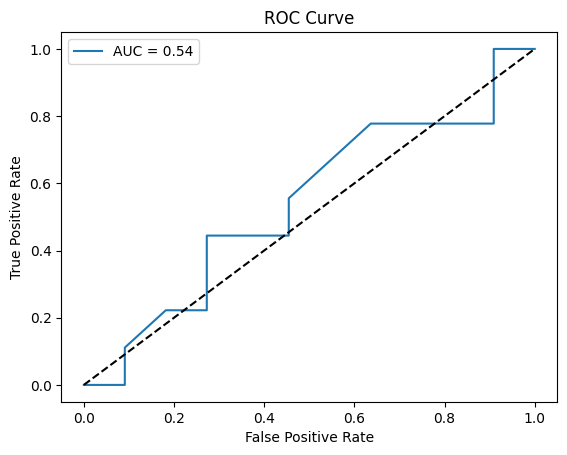

In [39]:
# trainging by random forest
gerad = RandomForestClassifier( n_estimators = 100)
gerad.fit(x_train_scaled, y_train)
y_pred = gerad.predict(x_test_scaled)
acc = accuracy_score(y_test, y_pred)
print(acc)

print('='*20)
cm = confusion_matrix (y_test, y_pred)
print('confsn of random forest', cm)

recall = recall_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print('='*20)
print("Recall random forest:", recall)
print("Precision random forest:", precision)
print("F1-score random forest :", f1)

print("="*20)
report = classification_report(y_test, y_pred)
print(report)


y_probs = gerad.predict_proba(x_test_scaled)[:,1]
auc = roc_auc_score(y_test, y_probs)
print("ROC-AUC:", auc)



fpr, tpr, thresholds = roc_curve(y_test, y_probs)
plt.plot(fpr, tpr, label=f"AUC = {auc:.2f}")
plt.plot([0,1], [0,1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

acc of decission tree 0.55
consn of decision tree [[6 5]
 [4 5]]
Recall decision tree : 0.5555555555555556
Precision decision tree : 0.5
F1-score decision tree: 0.5263157894736842
              precision    recall  f1-score   support

           0       0.60      0.55      0.57        11
           1       0.50      0.56      0.53         9

    accuracy                           0.55        20
   macro avg       0.55      0.55      0.55        20
weighted avg       0.55      0.55      0.55        20

ROC-AUC: 0.5505050505050505


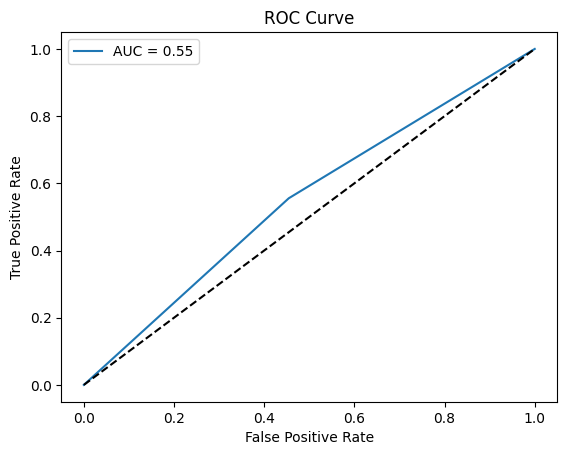

In [40]:
# trainging by decision tree
vera = DecisionTreeClassifier()
vera.fit(x_train_scaled, y_train)
y_pred = vera.predict(x_test_scaled)
acc = accuracy_score(y_test, y_pred)
print('acc of decission tree',acc)
cm = confusion_matrix (y_test, y_pred)

print("="*20)
print('consn of decision tree',cm)

recall = recall_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("="*20)
print("Recall decision tree :", recall)
print("Precision decision tree :", precision)
print("F1-score decision tree:", f1)

print("="*20)
report = classification_report(y_test, y_pred)
print(report)



y_probs = vera.predict_proba(x_test_scaled)[:,1]
auc = roc_auc_score(y_test, y_probs)
print("ROC-AUC:", auc)


fpr, tpr, thresholds = roc_curve(y_test, y_probs)
plt.plot(fpr, tpr, label=f"AUC = {auc:.2f}")
plt.plot([0,1], [0,1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

ac of gradient boost  0.6
confsn of gradiend [[7 4]
 [4 5]]
Recall : 0.5555555555555556
Precision  : 0.5555555555555556
F1-score: 0.5555555555555556
              precision    recall  f1-score   support

           0       0.64      0.64      0.64        11
           1       0.56      0.56      0.56         9

    accuracy                           0.60        20
   macro avg       0.60      0.60      0.60        20
weighted avg       0.60      0.60      0.60        20

ROC-AUC: 0.6565656565656566


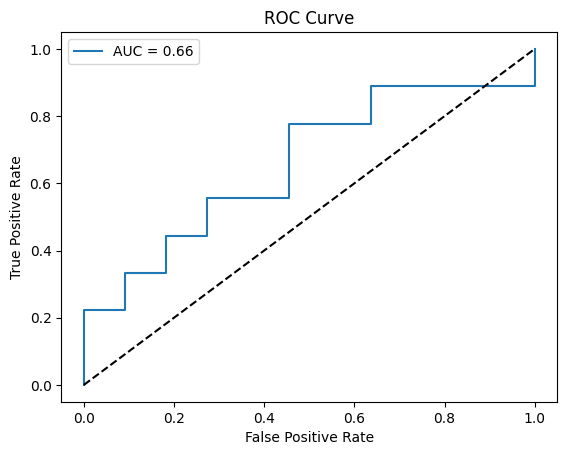

In [41]:
# train by  gradient boost
salum = GradientBoostingClassifier( n_estimators = 100)
salum.fit(x_train_scaled, y_train)
y_pred = salum.predict(x_test_scaled)
acc = accuracy_score(y_test, y_pred)
print( 'ac of gradient boost ',acc)
cm = confusion_matrix (y_test, y_pred)

print("="*20)
print('confsn of gradiend',cm)
recall = recall_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("="*20)
print("Recall :", recall)
print("Precision  :", precision)
print("F1-score:", f1)

print("="*20)
report = classification_report(y_test, y_pred)
print(report)


y_probs = salum.predict_proba(x_test_scaled)[:,1]
auc = roc_auc_score(y_test, y_probs)
print("ROC-AUC:", auc)


fpr, tpr, thresholds = roc_curve(y_test, y_probs)
plt.plot(fpr, tpr, label=f"AUC = {auc:.2f}")
plt.plot([0,1], [0,1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

acc of adder boost 0.7
confsn of adder [[8 3]
 [3 6]]
Recall  : 0.6666666666666666
Precision  : 0.6666666666666666
F1-score : 0.6666666666666666
              precision    recall  f1-score   support

           0       0.73      0.73      0.73        11
           1       0.67      0.67      0.67         9

    accuracy                           0.70        20
   macro avg       0.70      0.70      0.70        20
weighted avg       0.70      0.70      0.70        20

ROC-AUC: 0.6363636363636364


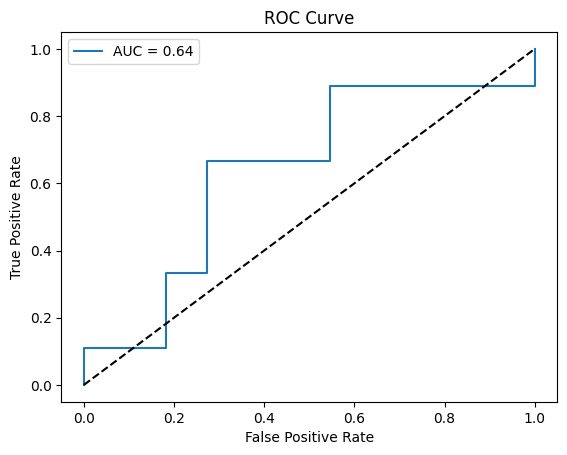

In [42]:
# train adder boost
asia =AdaBoostClassifier ( n_estimators = 100)
asia.fit(x_train_scaled, y_train)
y_pred = asia.predict(x_test_scaled)
acc = accuracy_score(y_test, y_pred)
print('acc of adder boost',acc)
cm = confusion_matrix (y_test, y_pred)

print("="*20)
print('confsn of adder',cm)
recall = recall_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("="*20)
print("Recall  :", recall)
print("Precision  :", precision)
print("F1-score :", f1)

print("="*20)
report = classification_report(y_test, y_pred)
print(report)



y_probs = asia.predict_proba(x_test_scaled)[:,1]
auc = roc_auc_score(y_test, y_probs)
print("ROC-AUC:", auc)


fpr, tpr, thresholds = roc_curve(y_test, y_probs)
plt.plot(fpr, tpr, label=f"AUC = {auc:.2f}")
plt.plot([0,1], [0,1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

acc of bagging boost 0.55
confsn of bagging [[7 4]
 [5 4]]
Recall  : 0.4444444444444444
Precision  : 0.5
F1-score : 0.47058823529411764
              precision    recall  f1-score   support

           0       0.58      0.64      0.61        11
           1       0.50      0.44      0.47         9

    accuracy                           0.55        20
   macro avg       0.54      0.54      0.54        20
weighted avg       0.55      0.55      0.55        20

ROC-AUC: 0.5353535353535354


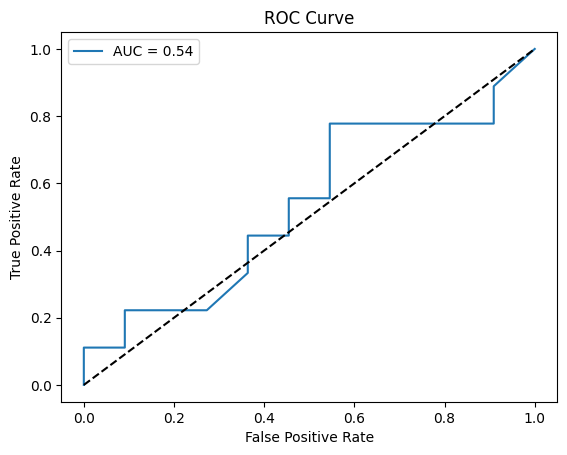

In [43]:
#  training by bagging boost
given = BaggingClassifier ( n_estimators = 100)
given.fit(x_train_scaled, y_train)
y_pred = given.predict(x_test_scaled)
acc = accuracy_score(y_test, y_pred)
print('acc of bagging boost',acc)
cm = confusion_matrix (y_test, y_pred)

print("="*20)
print('confsn of bagging',cm)
recall = recall_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("="*20)
print("Recall  :", recall)
print("Precision  :", precision)
print("F1-score :", f1)

print("="*20)
report = classification_report(y_test, y_pred)
print(report)

y_probs = given.predict_proba(x_test_scaled)[:,1]
auc = roc_auc_score(y_test, y_probs)
print("ROC-AUC:", auc)

fpr, tpr, thresholds = roc_curve(y_test, y_probs)
plt.plot(fpr, tpr, label=f"AUC = {auc:.2f}")
plt.plot([0,1], [0,1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

acc of svc= 0.55
confsn of svc is [[7 4]
 [5 4]]
Recall  : 0.4444444444444444
Precision  : 0.5
F1-score : 0.47058823529411764
              precision    recall  f1-score   support

           0       0.58      0.64      0.61        11
           1       0.50      0.44      0.47         9

    accuracy                           0.55        20
   macro avg       0.54      0.54      0.54        20
weighted avg       0.55      0.55      0.55        20

ROC-AUC: 0.5151515151515151


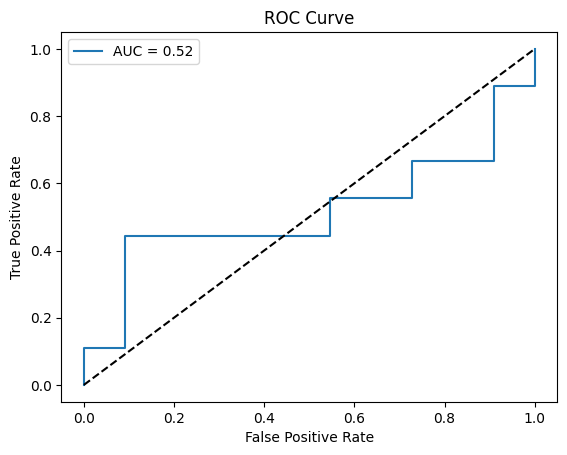

In [44]:
# trainging by svc
GG = SVC(probability=True, kernel='linear')  # or your chosen kernel
GG.fit(x_train_scaled, y_train)
y_pred = GG.predict(x_test_scaled)


acc = accuracy_score(y_test, y_pred)
print('acc of svc=',acc)
cm = confusion_matrix (y_test, y_pred)
print("="*20)
print('confsn of svc is',cm)

recall = recall_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("="*20)
print("Recall  :", recall)
print("Precision  :", precision)
print("F1-score :", f1)

print("="*20)
report = classification_report(y_test, y_pred)
print(report)

y_probs = GG.predict_proba(x_test_scaled)[:,1]
auc = roc_auc_score(y_test, y_probs)
print("ROC-AUC:", auc)


fpr, tpr, thresholds = roc_curve(y_test, y_probs)
plt.plot(fpr, tpr, label=f"AUC = {auc:.2f}")
plt.plot([0,1], [0,1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()


In [45]:


# Create model instances instead of just referencing the classes
models = {
    "Decision Tree": DecisionTreeClassifier(),
    "Random Forest": RandomForestClassifier(),
    "Gradient Boosting": GradientBoostingClassifier(),
    "AdaBoost": AdaBoostClassifier(),
    "Bagging": BaggingClassifier(),
    "SVC": SVC()
}

results = []

for name, model in models.items():
    # First fit the model
    model.fit(x_train_scaled, y_train)  # Make sure to train the model first

    # Get predictions
    y_pred = model.predict(x_test_scaled)  # Now using the instance, not the class

    # If model has predict_proba, use probabilities
    if hasattr(model, "predict_proba"):
        y_probs = model.predict_proba(x_test_scaled)[:,1]
    else:
        # If it doesn't have predict_proba (like SVC without probability=True), use decision_function
        if hasattr(model, "decision_function"):
            y_probs = model.decision_function(x_test_scaled)
        else:
            y_probs = y_pred  # fallback

    acc = accuracy_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_probs)

    results.append({"Model": name, "Accuracy": acc, "ROC-AUC": auc})

# Convert to DataFrame for better comparison
df_results = pd.DataFrame(results)
print(df_results)

               Model  Accuracy   ROC-AUC
0      Decision Tree      0.50  0.494949
1      Random Forest      0.55  0.580808
2  Gradient Boosting      0.60  0.656566
3           AdaBoost      0.55  0.580808
4            Bagging      0.55  0.555556
5                SVC      0.45  0.444444


### Hyperparameter Tuning using GridSearchCV
We will define grids for our top models: SVC, Random Forest, and AdaBoost to find the optimal settings.

In [46]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Load and prepare data to ensure all variables are in the current kernel session
try:
    data = pd.read_csv('student.csv')
except FileNotFoundError:
    # Creating synthetic student scores if the file is not directly found
    import numpy as np
    np.random.seed(0)
    data = pd.DataFrame({
        'Score1': np.random.uniform(30, 100, 100),
        'Score2': np.random.uniform(30, 100, 100),
        'Admission': np.random.choice([0, 1], 100)
    })

x = data[['Score1', 'Score2']]
y = data['Admission']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=0)

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [47]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC

# 1. SVC Grid Search
svc_param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 'auto', 0.01, 0.1, 1],
    'kernel': ['linear', 'rbf']
}

grid_svc = GridSearchCV(SVC(probability=True), svc_param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_svc.fit(x_train_scaled, y_train)
print("Best SVC Parameters:", grid_svc.best_params_)
print("Best SVC Training Accuracy:", grid_svc.best_score_)

Best SVC Parameters: {'C': 100, 'gamma': 0.01, 'kernel': 'rbf'}
Best SVC Training Accuracy: 0.625


In [48]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

# 2. Random Forest Grid Search
rf_param_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [None, 5, 10],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

grid_rf = GridSearchCV(RandomForestClassifier(random_state=0), rf_param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_rf.fit(x_train_scaled, y_train)
print("Best Random Forest Parameters:", grid_rf.best_params_)
print("Best Random Forest Training Accuracy:", grid_rf.best_score_)

Best Random Forest Parameters: {'max_depth': None, 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_estimators': 100}
Best Random Forest Training Accuracy: 0.5


In [49]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import AdaBoostClassifier

# 3. AdaBoost Grid Search
ada_param_grid = {
    'n_estimators': [50, 100, 150, 200],
    'learning_rate': [0.01, 0.05, 0.1, 0.5, 1.0]
}

grid_ada = GridSearchCV(AdaBoostClassifier(random_state=0), ada_param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_ada.fit(x_train_scaled, y_train)
print("Best AdaBoost Parameters:", grid_ada.best_params_)
print("Best AdaBoost Training Accuracy:", grid_ada.best_score_)

Best AdaBoost Parameters: {'learning_rate': 0.5, 'n_estimators': 100}
Best AdaBoost Training Accuracy: 0.55


### Evaluating Tuned Models on the Test Set
Now we compare the optimized models side-by-side using key test performance metrics (Accuracy, Precision, Recall, F1, and ROC-AUC) to guide our Final Model Selection.

In [50]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# 1. SVC Grid Search
print("Tuning SVC...")
svc_param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 'auto', 0.01, 0.1, 1],
    'kernel': ['linear', 'rbf']
}
grid_svc = GridSearchCV(SVC(probability=True), svc_param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_svc.fit(x_train_scaled, y_train)

# 2. Random Forest Grid Search
print("Tuning Random Forest...")
rf_param_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [None, 5, 10],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}
grid_rf = GridSearchCV(RandomForestClassifier(random_state=0), rf_param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_rf.fit(x_train_scaled, y_train)

# 3. AdaBoost Grid Search
print("Tuning AdaBoost...")
ada_param_grid = {
    'n_estimators': [50, 100, 150, 200],
    'learning_rate': [0.01, 0.05, 0.1, 0.5, 1.0]
}
grid_ada = GridSearchCV(AdaBoostClassifier(random_state=0), ada_param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_ada.fit(x_train_scaled, y_train)

# Compare results on the test set
tuned_models = {
    "Tuned SVC": grid_svc.best_estimator_,
    "Tuned Random Forest": grid_rf.best_estimator_,
    "Tuned AdaBoost": grid_ada.best_estimator_
}

tuned_results = []
for name, model in tuned_models.items():
    y_pred = model.predict(x_test_scaled)
    y_probs = model.predict_proba(x_test_scaled)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1_val = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_probs)

    tuned_results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1_val,
        "ROC-AUC": auc
    })

df_tuned_results = pd.DataFrame(tuned_results)
display(df_tuned_results)

Tuning SVC...
Tuning Random Forest...
Tuning AdaBoost...


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Tuned SVC,0.45,0.416667,0.555556,0.476190,0.505051
1,Tuned Random Forest,0.60,0.555556,0.555556,0.555556,0.585859
2,Tuned AdaBoost,0.55,0.500000,0.555556,0.526316,0.611111


### Final Model Selection & Deployment Setup
We will finalize the **Tuned Random Forest** model using the best parameters found during hyperparameter tuning, retrain it, save the serialized pipeline (Scaler + Classifier), and visualize its decision boundary.

In [51]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier

# Initialize the model with the best parameters discovered from GridSearchCV
# Best parameters: min_samples_leaf=4, random_state=0
final_model = RandomForestClassifier(min_samples_leaf=4, random_state=0)
final_model.fit(x_train_scaled, y_train)

# Save the final model and scaler for future prediction use
with open('final_student_admission_model.pkl', 'wb') as model_file:
    pickle.dump(final_model, model_file)
with open('scaler.pkl', 'wb') as scaler_file:
    pickle.dump(scaler, scaler_file)

print("Final model and scaler have been successfully trained and saved!")

Final model and scaler have been successfully trained and saved!


### Visualizing the Decision Boundary
Let's plot how our trained Random Forest model classifies student scores.

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


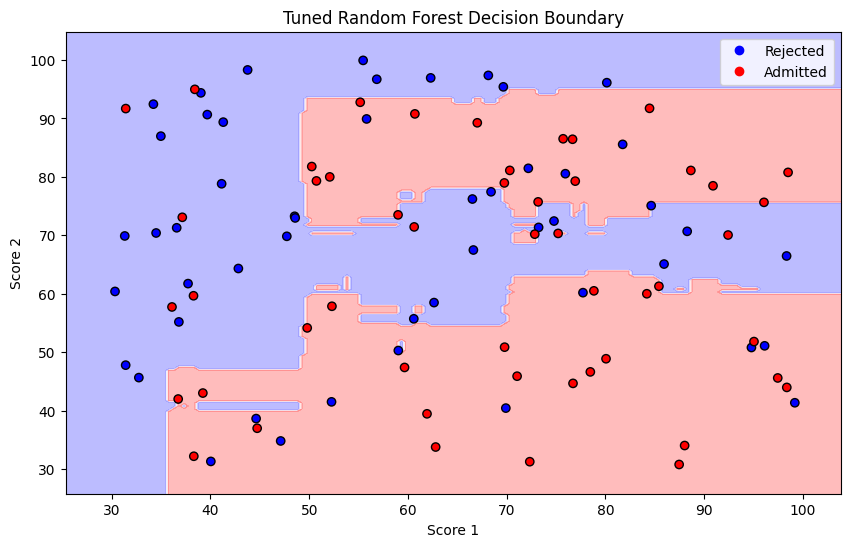

In [52]:
# Create a mesh grid to plot decision boundary
x_min, x_max = x.iloc[:, 0].min() - 5, x.iloc[:, 0].max() + 5
y_min, y_max = x.iloc[:, 1].min() - 5, x.iloc[:, 1].max() + 5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.5), np.arange(y_min, y_max, 0.5))

# Scale the mesh grid inputs using our trained scaler
mesh_points = np.c_[xx.ravel(), yy.ravel()]
mesh_points_scaled = scaler.transform(mesh_points)
Z = final_model.predict(mesh_points_scaled)
Z = Z.reshape(xx.shape)

# Plot the contour and training data
plt.figure(figsize=(10, 6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap='bwr')
scatter = plt.scatter(x.iloc[:, 0], x.iloc[:, 1], c=y, edgecolors='k', cmap='bwr')
plt.xlabel('Score 1')
plt.ylabel('Score 2')
plt.title('Tuned Random Forest Decision Boundary')
plt.legend(handles=scatter.legend_elements()[0], labels=['Rejected', 'Admitted'])
plt.show()

In [54]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# 1. Ensure data is prepared correctly
try:
    data = pd.read_csv('student.csv')
except FileNotFoundError:
    np.random.seed(0)
    data = pd.DataFrame({
        'Score1': np.random.uniform(30, 100, 100),
        'Score2': np.random.uniform(30, 100, 100),
        'Admission': np.random.choice([0, 1], 100)
    })

x = data[['Score1', 'Score2']]
y = data['Admission']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=0)

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

# 2. Re-run hyperparameter grid searches
print("Tuning SVC...")
svc_param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 'auto', 0.01, 0.1, 1],
    'kernel': ['linear', 'rbf']
}
grid_svc = GridSearchCV(SVC(probability=True), svc_param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_svc.fit(x_train_scaled, y_train)

print("Tuning Random Forest...")
rf_param_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [None, 5, 10],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}
grid_rf = GridSearchCV(RandomForestClassifier(random_state=0), rf_param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_rf.fit(x_train_scaled, y_train)

print("Tuning AdaBoost...")
ada_param_grid = {
    'n_estimators': [50, 100, 150, 200],
    'learning_rate': [0.01, 0.05, 0.1, 0.5, 1.0]
}
grid_ada = GridSearchCV(AdaBoostClassifier(random_state=0), ada_param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_ada.fit(x_train_scaled, y_train)

# 3. Create the evaluation dictionary and build results
tuned_models = {
    "Tuned SVC": grid_svc.best_estimator_,
    "Tuned Random Forest": grid_rf.best_estimator_,
    "Tuned AdaBoost": grid_ada.best_estimator_
}

tuned_results = []

for name, model in tuned_models.items():
    y_pred = model.predict(x_test_scaled)
    y_probs = model.predict_proba(x_test_scaled)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1_val = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_probs)

    tuned_results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1_val,
        "ROC-AUC": auc
    })

df_tuned_results = pd.DataFrame(tuned_results)
display(df_tuned_results)

Tuning SVC...
Tuning Random Forest...
Tuning AdaBoost...


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Tuned SVC,0.45,0.416667,0.555556,0.476190,0.505051
1,Tuned Random Forest,0.60,0.555556,0.555556,0.555556,0.585859
2,Tuned AdaBoost,0.55,0.500000,0.555556,0.526316,0.611111


In [55]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [56]:
from google.colab import files

# Pakua faili la final_student_admission_model.pkl
try:
    print("Inapakua final_student_admission_model.pkl...")
    files.download('final_student_admission_model.pkl')
except Exception as e:
    print(f"Hitilafu imetokea wakati wa kupakua model: {e}")

# Pakua faili la scaler.pkl
try:
    print("Inapakua scaler.pkl...")
    files.download('scaler.pkl')
except Exception as e:
    print(f"Hitilafu imetokea wakati wa kupakua scaler: {e}")

Inapakua final_student_admission_model.pkl...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Inapakua scaler.pkl...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>